# 02 — Build the fight-level dataset

Turns the raw Kaggle tables into one clean, chronological row per decided
fight, with the fighter-ordering leakage found in `ufc_event_fight_stats.csv`
removed (see `ROADMAP.md`).

All the actual transform logic lives in `src/ufc_predictor/data/` — this
notebook just calls it and checks the result. That split is deliberate: the
same `build_fight_dataset()` function is what a future incremental refresh
(new fights appended to `data/raw`) would call too, so the logic can't drift
between "what the notebook does" and "what the pipeline does".

In [1]:
from ufc_predictor.data.build import build_fight_dataset
from ufc_predictor.data.io import save_processed

fights = build_fight_dataset()
fights.shape

(7697, 61)

## Sanity checks

The things that would silently break the project if they were wrong.

In [2]:
# 7,840 raw fights minus 143 draws/no-contests
assert len(fights) == 7697
assert fights["event_date"].is_monotonic_increasing

overall_rate = fights["fighter_a_won"].mean()
print(f"fighter_a win rate, overall: {overall_rate:.3f}")
assert 0.45 < overall_rate < 0.55

fighter_a win rate, overall: 0.503


In [3]:
# the bug this notebook exists to fix: pre-2010, the raw data lists the
# winner as f1 for every single fight. after de-biasing, that block should
# look like any other era, not a flat 100%.
pre_2010 = fights[fights["event_date"].dt.year < 2010]
pre_2010_rate = pre_2010["fighter_a_won"].mean()
print(f"fighter_a win rate, pre-2010 ({len(pre_2010)} fights): {pre_2010_rate:.3f}")
assert 0.40 < pre_2010_rate < 0.60

fighter_a win rate, pre-2010 (1169 fights): 0.489


<Axes: title={'center': 'fighter_a win rate by year (should hover near 0.5 throughout)'}, xlabel='event_date'>

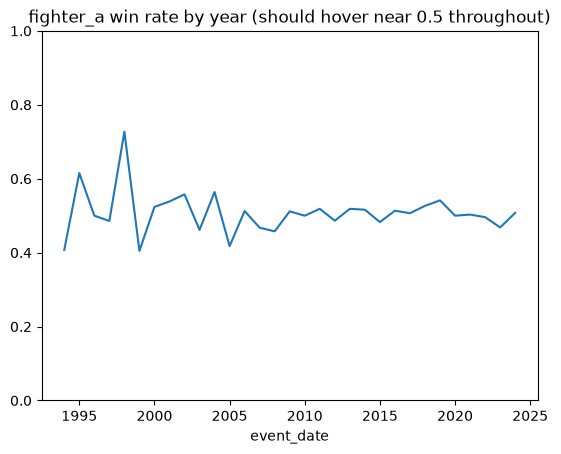

In [4]:
fights.groupby(fights["event_date"].dt.year)["fighter_a_won"].mean().plot(
    title="fighter_a win rate by year (should hover near 0.5 throughout)",
    ylim=(0, 1),
)

## Save

In [5]:
save_processed(fights, "fights")
fights.head()

,weight_class,result,fights_url,event_url,event_date,winner_id,fighter_a_age_during,fighter_b_age_during,fighter_a_body_strike_atts,fighter_b_body_strike_atts,...,fighter_b_takedown_atts,fighter_a_takedowns,fighter_b_takedowns,fighter_a_tot_strike_atts,fighter_b_tot_strike_atts,fighter_a_tot_strikes,fighter_b_tot_strikes,fighter_a_total_fight_time,fighter_b_total_fight_time,fighter_a_won
0,Open Weight Bout,2884,http://www.ufcstats.com/fight-details/17ee4caf...,http://www.ufcstats.com/event-details/a6a9ab5a...,1994-03-11,2884,NaN,NaN,0,0,...,1,0,1,11,22,9,20,591,591,False
1,Open Weight Bout,1396,http://www.ufcstats.com/fight-details/5655639b...,http://www.ufcstats.com/event-details/a6a9ab5a...,1994-03-11,1396,24.0,27.0,0,0,...,0,1,0,0,0,0,0,67,67,False
2,Open Weight Bout,1396,http://www.ufcstats.com/fight-details/aa161c71...,http://www.ufcstats.com/event-details/a6a9ab5a...,1994-03-11,1396,NaN,27.0,0,0,...,2,0,1,0,0,0,0,91,91,False
3,Open Weight Bout,890,http://www.ufcstats.com/fight-details/c53325be...,http://www.ufcstats.com/event-details/a6a9ab5a...,1994-03-11,890,NaN,24.0,0,2,...,1,1,0,23,25,14,20,401,401,False
4,Open Weight Bout,3594,http://www.ufcstats.com/fight-details/8ea72cf8...,http://www.ufcstats.com/event-details/a6a9ab5a...,1994-03-11,3594,NaN,30.0,0,1,...,0,0,0,0,25,0,19,30,30,False
